In [1]:
!wget -q -c https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz
!tar -xzf flower_photos.tgz

In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)

In [3]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        print(e)

1 Physical GPUs, 1 Logical GPUs


In [4]:
def plot_learning_curve(history):
    # Graficar exactitud
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('accuracy Curves')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()

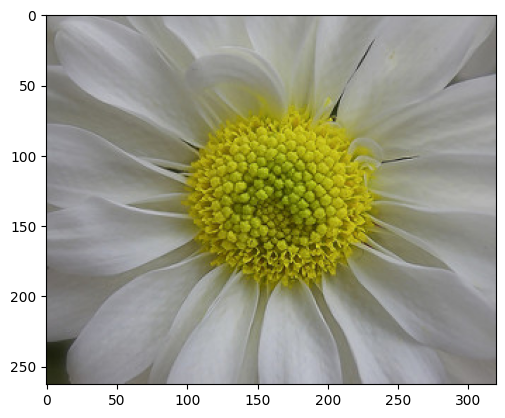

Format: JPEG, Size: (320, 263), Mode: RGB


In [5]:
from PIL import Image

img = Image.open('/content/flower_photos/daisy/100080576_f52e8ee070_n.jpg')
plt.imshow(img)
plt.show()
print(f"Format: {img.format}, Size: {img.size}, Mode: {img.mode}")

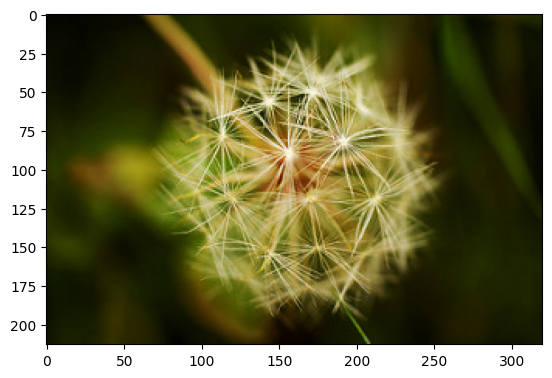

Format: JPEG, Size: (320, 213), Mode: RGB


In [6]:
img = Image.open('/content/flower_photos/dandelion/10043234166_e6dd915111_n.jpg')
plt.imshow(img)
plt.show()
print(f"Format: {img.format}, Size: {img.size}, Mode: {img.mode}")

In [7]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

df_train = tf.keras.utils.image_dataset_from_directory(
    "flower_photos",
    subset="training",
    seed = 20261031,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "int",
    validation_split = 0.2
)

df_val = tf.keras.utils.image_dataset_from_directory(
    "flower_photos",
    subset="validation",
    seed = 20261031,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "int",
    validation_split = 0.2
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.


(224, 224, 3)
sunflowers


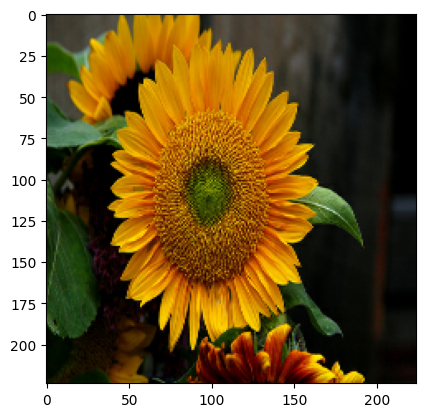

(224, 224, 3)
daisy


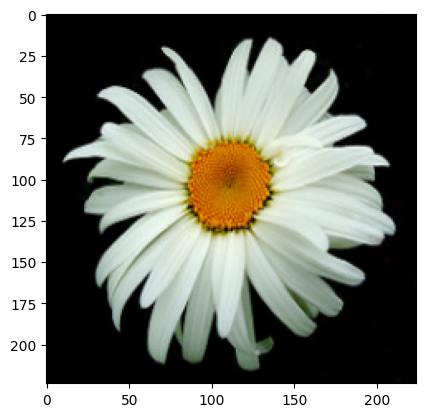

(224, 224, 3)
daisy


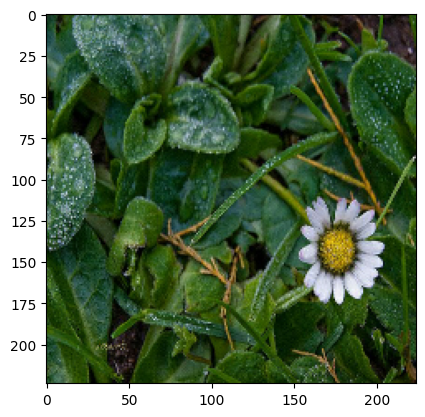

(224, 224, 3)
sunflowers


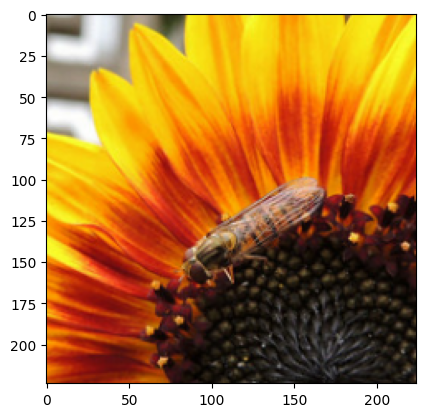

(224, 224, 3)
tulips


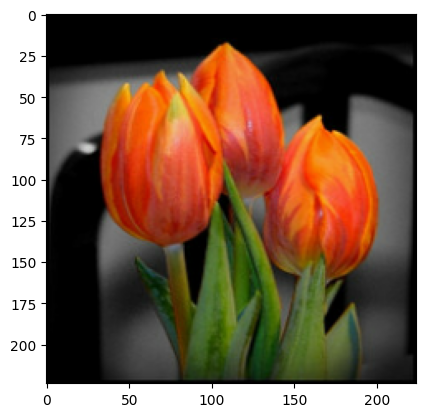

In [8]:
numpy_iterator = df_train.as_numpy_iterator()
for batch_images, batch_labels in numpy_iterator:
    for i in range(5):
      print(batch_images[i].shape)
      print(df_train.class_names[batch_labels[i]])
      plt.imshow(batch_images[i].astype("uint8"))
      plt.show()
    break

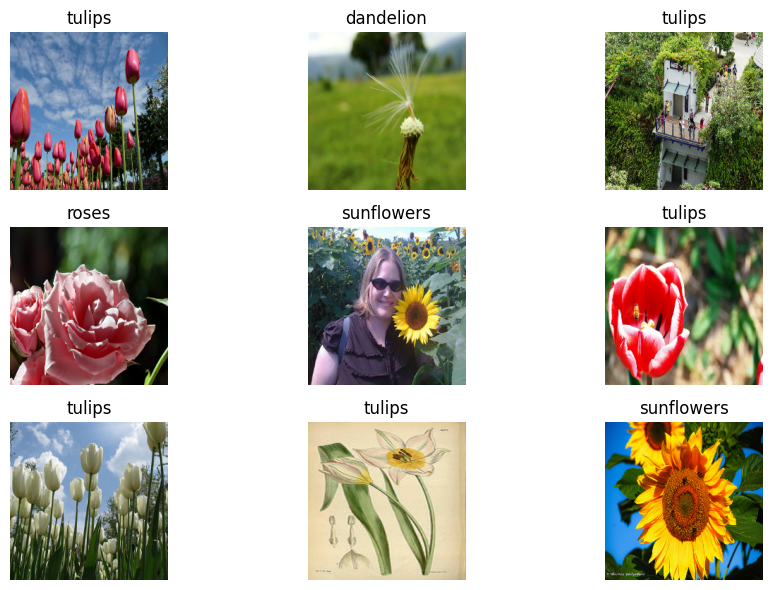

In [9]:
class_names = df_train.class_names
class_names

train_ds = df_train.take(15).cache().prefetch(tf.data.AUTOTUNE)
val_ds = df_val.take(10).cache().prefetch(tf.data.AUTOTUNE)

plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()


In [10]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.4),
    tf.keras.layers.RandomZoom(0.4)
], name = "data_augemtation")

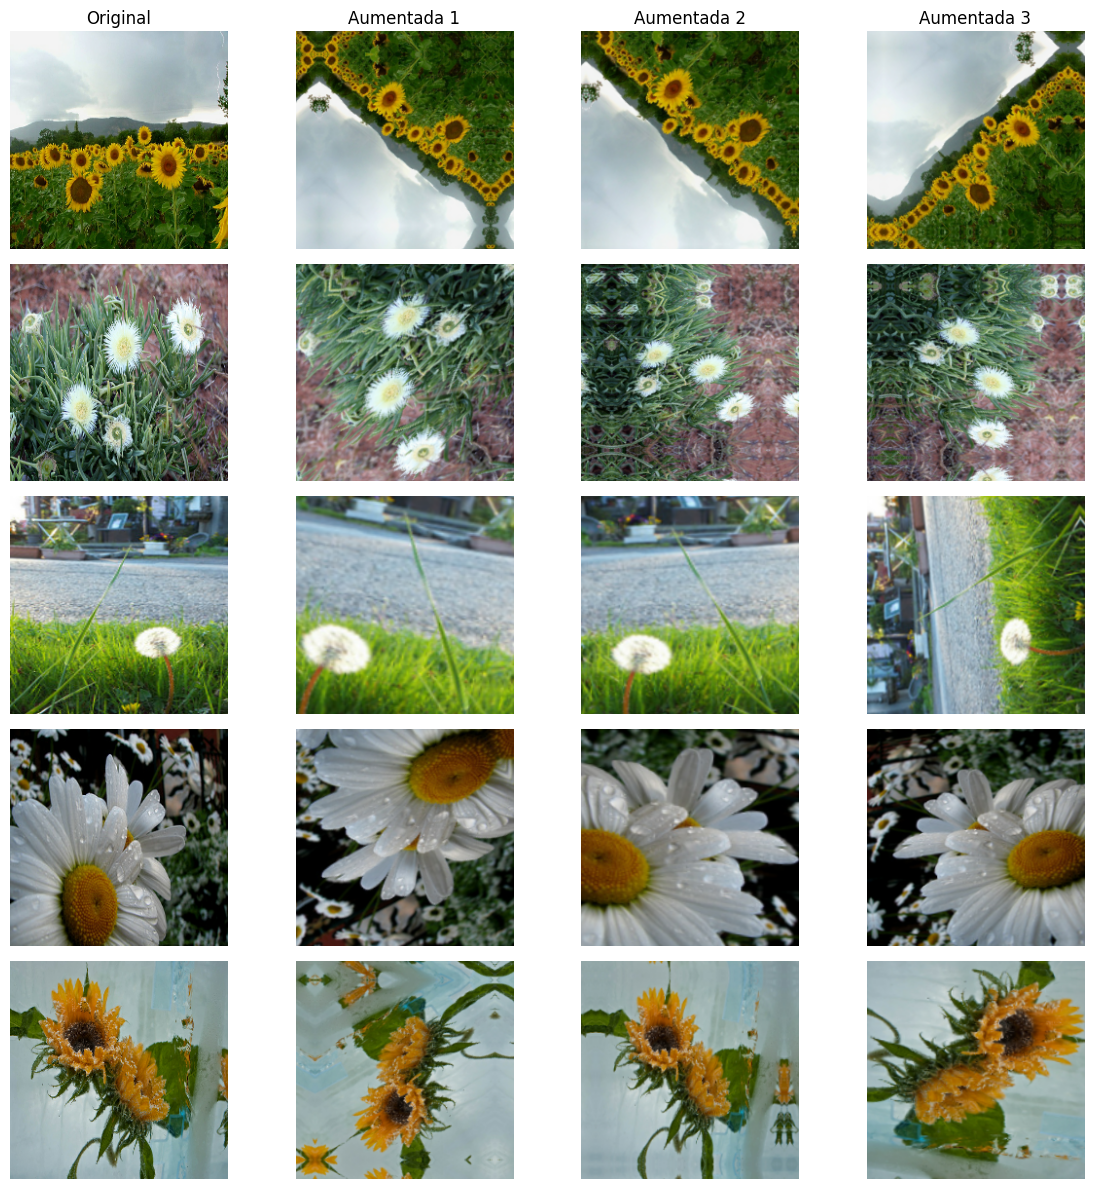

In [11]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Tomamos un batch de imágenes para extraer 5 de ellas
for images, _ in train_ds.take(1):
    num_images = 5

    # Configuramos la figura: 5 filas (una por imagen) y 4 columnas (original + 3 aumentadas)
    fig, axes = plt.subplots(num_images, 4, figsize=(12, 12))

    for i in range(num_images):
        img = images[i]

        # Mostrar la imagen original
        axes[i, 0].imshow(img.numpy().astype("uint8"))
        if i == 0:
            axes[i, 0].set_title("Original", fontsize=12)
        axes[i, 0].axis("off")

        # Generar y mostrar 3 variaciones aumentadas de la misma imagen
        for j in range(1, 4):
            # El pipeline de aumento espera un batch, por lo que expandimos las dimensiones
            augmented_img = data_augmentation(tf.expand_dims(img, 0), training=True)
            axes[i, j].imshow(augmented_img[0].numpy().astype("uint8"))
            if i == 0:
                axes[i, j].set_title(f"Aumentada {j}", fontsize=12)
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.show()
    break

## Transfer Learning

In [12]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape = (224, 224, 3),
    include_top = False,
    weights = "imagenet",
)

base_model.trainable = False

In [13]:
inputs = tf.keras.layers.Input(shape = (224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)
x = base_model(x, training = False)
x = tf.keras.layers.Flatten()(x)
outputs = tf.keras.layers.Dense(units = 5, activation = "softmax")(x)

transfer_model = tf.keras.Model(inputs, outputs, name = "MobileNetV2_TransferLearning")
fine_tunning_model  = tf.keras.Model(inputs, outputs, name = "MobileNetV2_FineTunning")

In [14]:
transfer_model.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [15]:
transfer_model.summary()

Model: "MobileNetV2_TransferLearning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augemtation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 62720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │       313,605 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,571,589 (9.81 MB)

 Trainable params: 313,605 (1.20 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
print(f"Parámetros entrenables: {sum(tf.size(w).numpy() for w in transfer_model.trainable_weights):,}")

Parámetros entrenables: 313,605


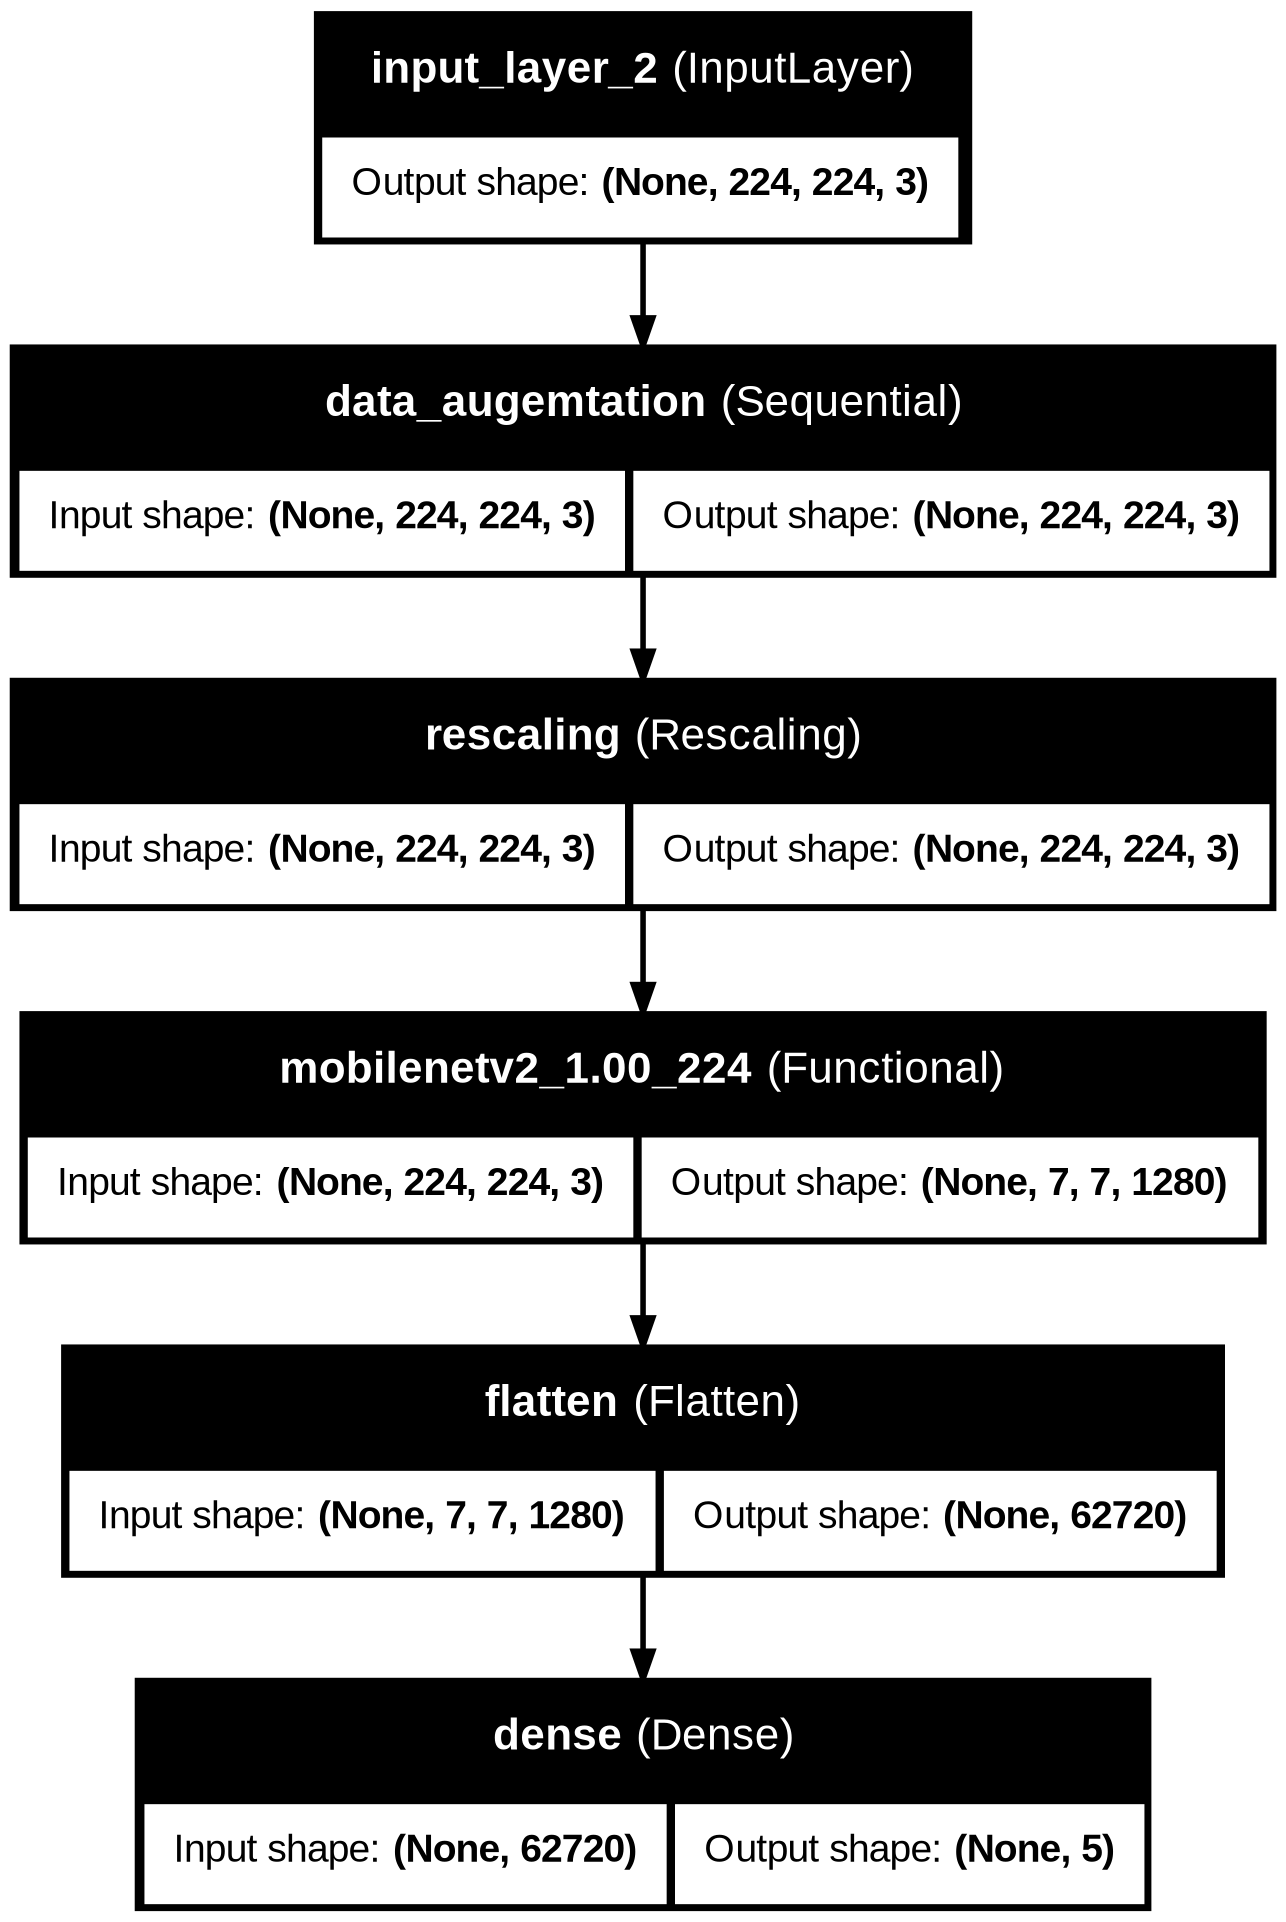

In [17]:
tf.keras.utils.plot_model(
    transfer_model,
    show_shapes=True,
    show_layer_names=True,
    to_file="mobilenetv2.png",
)

from IPython.display import Image
Image("mobilenetv2.png")

In [18]:
history_transfer_learning = transfer_model.fit(
    df_train,
    epochs = 10,
    validation_data = df_val
)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 100ms/step - accuracy: 0.7166 - loss: 3.5025 - val_accuracy: 0.8215 - val_loss: 1.4913
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step - accuracy: 0.8007 - loss: 2.4664 - val_accuracy: 0.8297 - val_loss: 1.8052
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.8317 - loss: 1.9986 - val_accuracy: 0.8406 - val_loss: 2.1673
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.8365 - loss: 2.0114 - val_accuracy: 0.8433 - val_loss: 2.5404
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.8522 - loss: 2.1493 - val_accuracy: 0.8420 - val_loss: 2.4181
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 83ms/step - accuracy: 0.8665 - loss: 1.8269 - val_accuracy: 0.8747 - val_loss: 2.1906
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.8655 - loss: 1.9828 - val_accuracy: 0.8678 - val_loss: 2.6441
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 83ms/step - accuracy: 0.8658 - loss: 1.9125 - val_accuracy: 0.8447 -

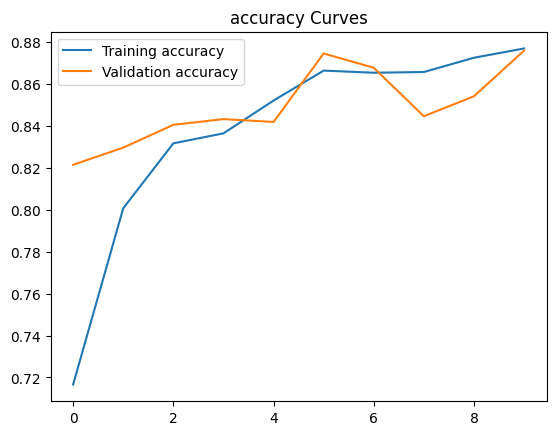

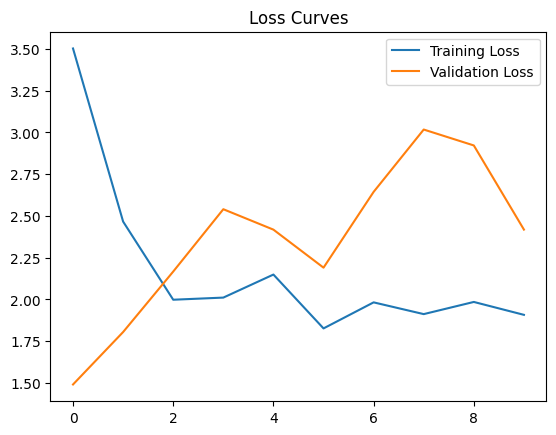

In [19]:
plot_learning_curve(history_transfer_learning)

## Fine Tunning

In [20]:
base_model.trainable = True

for layer in base_model.layers[:150]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [21]:
fine_tunning_model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate = 0.000001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [22]:
fine_tunning_model.summary()

Model: "MobileNetV2_FineTunning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augemtation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 62720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │       313,605 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,571,589 (9.81 MB)

 Trainable params: 723,205 (2.76 MB)

 Non-trainable params: 1,848,384 (7.05 MB)

In [23]:
print(f"Parámetros entrenables: {sum(tf.size(w).numpy() for w in fine_tunning_model.trainable_weights):,}")

Parámetros entrenables: 723,205


In [24]:
history_fine_tunning = fine_tunning_model.fit(
    df_train,
    epochs = 30,
    validation_data = df_val
)

Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 96ms/step - accuracy: 0.8985 - loss: 1.3547 - val_accuracy: 0.8787 - val_loss: 2.3969
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.9067 - loss: 1.4511 - val_accuracy: 0.8815 - val_loss: 2.3818
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.9012 - loss: 1.4304 - val_accuracy: 0.8842 - val_loss: 2.3774
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.8941 - loss: 1.6090 - val_accuracy: 0.8869 - val_loss: 2.3669
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.9087 - loss: 1.4403 - val_accuracy: 0.8856 - val_loss: 2.3574
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.9094 - loss: 1.3560 - val_accuracy: 0.8842 - val_loss: 2.3480
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.9019 - loss: 1.4979 - val_accuracy: 0.8842 - val_loss: 2.3385
Epoch 8/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.9057 - loss: 1.2863 - val_accuracy: 0.882

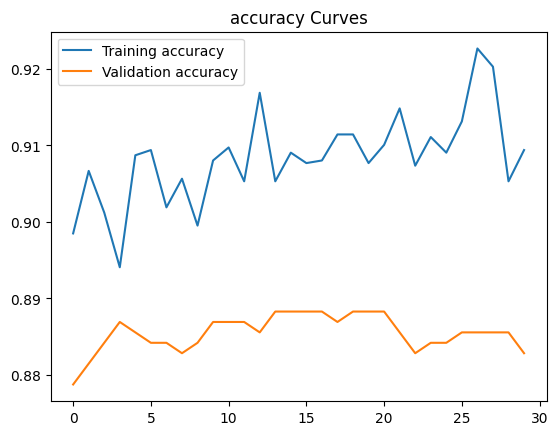

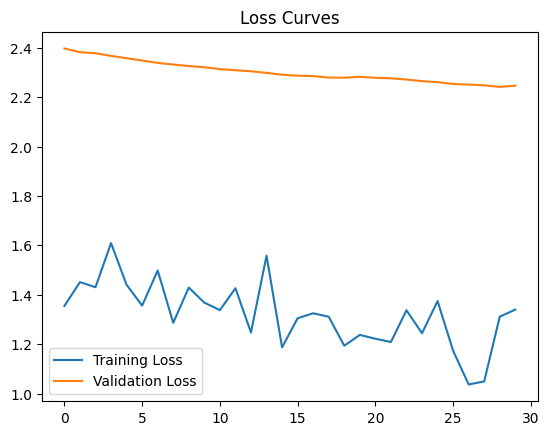

In [25]:
plot_learning_curve(history_fine_tunning)